<a href="https://colab.research.google.com/github/kfei-21/IE-7615-Generative-Project/blob/main/notebooks/03_eval_sets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 2 – Evaluation Sets

Fixes the **prompt set** used by every Milestone 2 sweep and the **real-image reference set** for FID in Milestone 3. Both are saved to files so every teammate's notebook reads the same lists.

**Inputs**
- `data/manifest.csv` and `data/processed_512/` (from `01_data_prep`)
- `embeddings/text_embeddings_sd15_caption.pt`, `embeddings/text_embeddings_sd21_caption.pt` (from `02_text_embeddings_*`)
- `results/milestone1/token_stats_sd15_caption.csv`, `results/milestone1/token_stats_sd21_caption.csv`

**Outputs**
- `data/prompt_set_m2.csv`: 10 prompts with `image_id`, `category`, `caption`, `emb_row` (row index into both embedding files) and `file_path`
- `data/fid_reference_ids.json`: 1,000 seeded image IDs (seed 42) for the FID reference set
- `results/milestone2/prompt_set_m2.png`: preview grid of the prompt set

**Prompt set**: the 5 Milestone 1 test prompts (counting, people and action, spatial relation, simple scene, two objects), kept so results line up with Milestone 1, plus 5 new difficulty types found by keyword search: colour binding, visible text, crowd, food close-up and cluttered indoor scene.

**Run order**: no GPU needed (CPU runtime). Run all. If pip changes any package in the first cell, restart the session and run all again. With `OVERWRITE = False`, sections that save files compare against the existing files instead and stop if they differ, so the lists cannot change silently after sweeps have started.

## 1. Setup and config
Mounts the shared Drive folder and installs the pinned library versions from `requirements.txt`. `PROMPT_IDS` maps each `image_id` to its difficulty category. The first five are the Milestone 1 test prompts. `FID_N = 1000` was chosen as a balance between FID reliability (features are 2048-dimensional) and Milestone 3 generation time (about 4–5 s per image on a T4).

In [1]:
from pathlib import Path
from importlib.metadata import version


try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path("/content/drive/MyDrive/IE7615_Project2")
except ImportError:
    ROOT = Path("./IE7615_Project2")

REQ = ROOT / "requirements.txt"
if REQ.exists():
    !pip -q install -r "{REQ}"
print(REQ.read_text())

Mounted at /content/drive
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.29.1+cpu requires torch>=2.14.0, but you have torch 2.11.0 which is incompatible.
torch==2.11.0
diffusers==0.42.1
transformers==5.22.0
accelerate==1.15.0



In [2]:
import json, random, textwrap
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
#config
SEED        = 42
CAPTION_COL = "caption"
MODEL_TAGS  = ["sd15", "sd21"]
OVERWRITE   = False
#test prompts
PROMPT_IDS = {
    1761:  "counting",
    97924: "people_action",
    25181: "spatial_relation",
    3661:  "simple_scene",
    5600:  "two_objects",
    27972:  "colour_binding",
    214200: "visible_text",
    12670:  "crowd",
    88269:  "food_closeup",
    7574:   "cluttered_indoor",
}



FID_N = 1000
DATA        = ROOT / "data"
EMB_DIR     = ROOT / "embeddings"
M1_RESULTS  = ROOT / "results" / "milestone1"
M2_RESULTS  = ROOT / "results" / "milestone2"
M2_RESULTS.mkdir(parents=True, exist_ok=True)

PROMPT_FILE = DATA / "prompt_set_m2.csv"
FID_FILE    = DATA / "fid_reference_ids.json"

random.seed(SEED); np.random.seed(SEED)

## Load manifest, token stats and embedding IDs

In [4]:
manifest = pd.read_csv(DATA / "manifest.csv")
assert manifest["image_id"].is_unique
by_id = manifest.set_index("image_id")
print(manifest.shape)

tok_stats = {t: pd.read_csv(M1_RESULTS / f"token_stats_{t}_{CAPTION_COL}.csv").set_index("image_id")
             for t in MODEL_TAGS}


emb_ids = {}
for t in MODEL_TAGS:
    e = torch.load(EMB_DIR / f"text_embeddings_{t}_{CAPTION_COL}.pt", map_location="cpu")
    emb_ids[t] = e["image_ids"]
    assert emb_ids[t] == manifest["image_id"].tolist(), f"{t}: embedding order differs from manifest"
    print(t, "| checkpoint:", e["checkpoint"], "| revision:", e["revision"][:10], "| n:", len(emb_ids[t]))
    del e


(2000, 3)
sd15 | checkpoint: stable-diffusion-v1-5/stable-diffusion-v1-5 | revision: 451f4fe161 | n: 2000
sd21 | checkpoint: sd2-community/stable-diffusion-2-1-base | revision: 4e63672c03 | n: 2000


## Helper: preview real images
`show()` displays real COCO images with their ID, category and caption, used to check candidates before choosing them.

In [5]:
def show(ids, ncols=5, save=None, title=None):
    ids = list(ids)
    nrows = -(-len(ids) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 4.4 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, iid in zip(axes.flat, ids):
        row = by_id.loc[iid]
        ax.imshow(Image.open(DATA / row["file_path"]))
        label = f"{iid}"
        if iid in PROMPT_IDS:
            label += f" | {PROMPT_IDS[iid]}"
        ax.set_title(label + "\n" + "\n".join(textwrap.wrap(row[CAPTION_COL], 34)), fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=120, bbox_inches="tight")
    plt.show()

## Keyword search for new difficulty types
Milestone 1 found that COCO captions rarely describe layout, so this searches for properties they do describe: colours, visible text, crowds, food and indoor clutter. Milestone 1 IDs are excluded from the hits.

In [6]:
KEYWORDS = [" red ", " blue ", " green ", " yellow ",      # colour / attribute binding
            " sign", " reads ", " says ",                    # visible text
            " people ", " group of ", " crowd",              # many people
            " plate of ", " pizza", " sandwich",             # food close-ups
            " kitchen ", " living room", " cluttered"]       # cluttered indoor scenes

for word in KEYWORDS:
    hits = manifest[manifest[CAPTION_COL].str.contains(word, case=False, regex=False)
                    & ~manifest["image_id"].isin(PROMPT_IDS)]
    print(f"{word!r}: {len(hits)}")
    print(hits[["image_id", CAPTION_COL]].head(5).to_string(index=False), "\n")

' red ': 65
 image_id                                                         caption
     8899             A red brick building with a graffiti covered front.
    15272 A red light is a wonderful contrast to the pink leaves on trees
    31735        A red living room filled with furniture and two windows.
    44068                      A brown teddy bear sitting in a red chair.
    60855                Five oranges with a red apple and a green apple. 

' blue ': 44
 image_id                                                                                    caption
      632                                  Bedroom scene with a bookcase, blue comforter and window.
    27932                                     A catchers mitt sitting inside of a blue baseball hat.
    52017                                              A yellow and blue plant flying in a gray sky.
    93261 A man in blue shorts putting together a blue and purple kite on a blue towel at the beach.
    95899               

### Reviewing candidates
Captions can match a keyword but describe the image poorly. 208423 ("a crowd of people flying kites over a field") was dropped because no crowd is visible and the kites are tiny. Of the two colour-binding options, 27972 (three colours on three objects) was chosen over 44068 as the harder test.

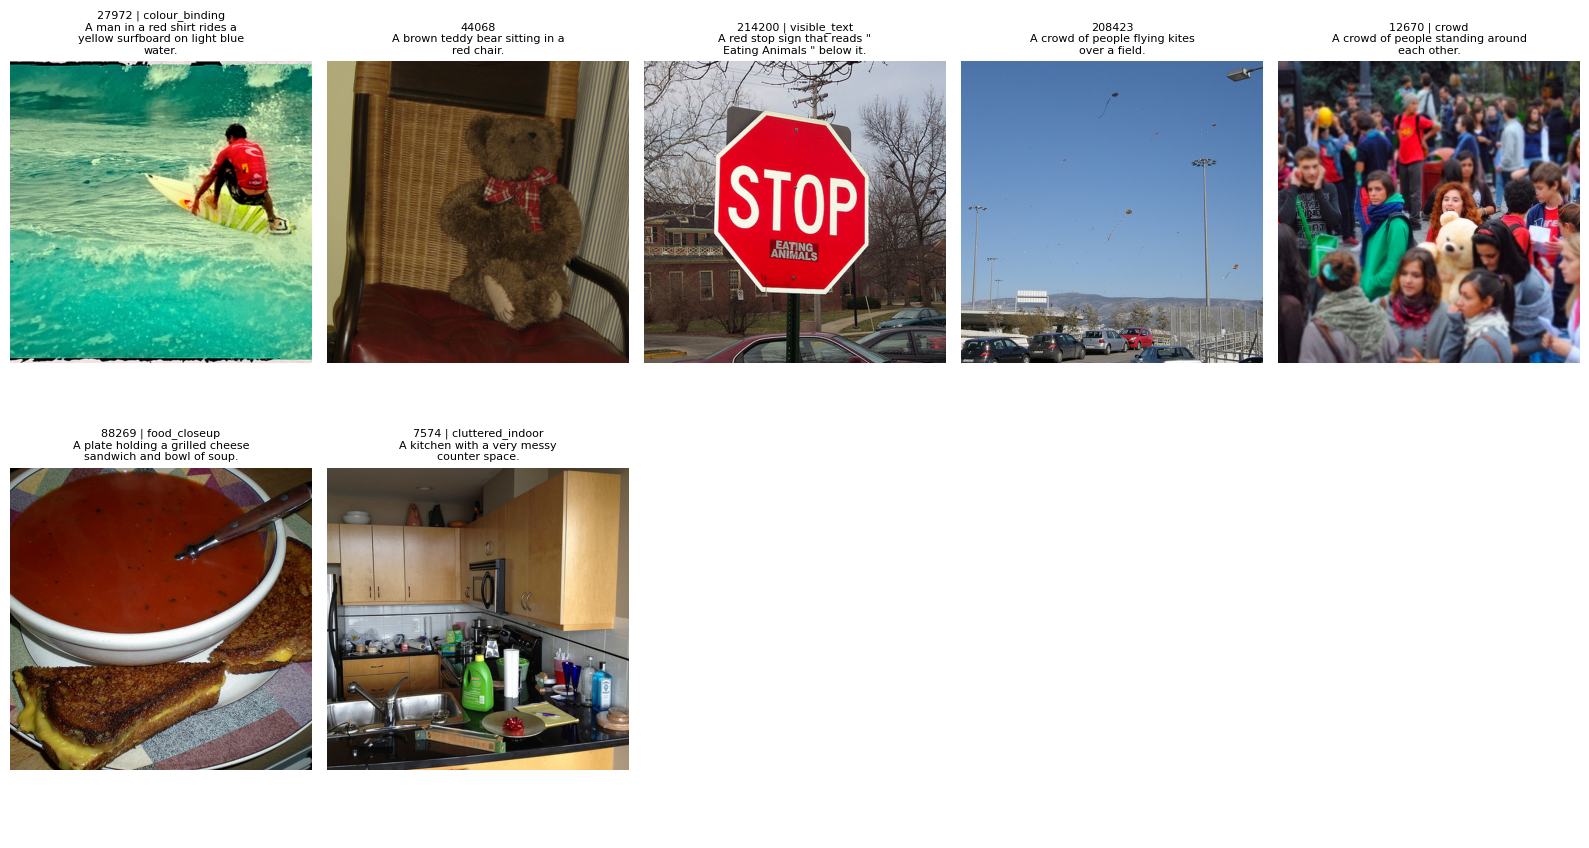

In [7]:

candidates = [27972, 44068, 214200, 208423, 12670, 88269, 7574]
if candidates:
    show(candidates)

## Validate the prompt set
Each ID must be in the manifest, have an image on Drive, appear in both embedding files, and not be truncated by either tokenizer.

In [8]:
ids = list(PROMPT_IDS)
print(f"{len(ids)} prompt IDs")
if len(ids) < 10:
    print("Warning: fewer than 10 prompts; add the new categories in 1.1")

problems = []
for iid in ids:
    if iid not in by_id.index:
        problems.append(f"{iid}: not in manifest")
        continue
    if not (DATA / by_id.loc[iid, "file_path"]).exists():
        problems.append(f"{iid}: image file missing")
    for t in MODEL_TAGS:
        if iid not in emb_ids[t]:
            problems.append(f"{iid}: not in {t} embeddings")
        elif bool(tok_stats[t].loc[iid, "truncated"]):
            problems.append(f"{iid}: caption truncated by {t} tokenizer")

assert not problems, "\n".join(problems)
print("All prompt IDs valid")

10 prompt IDs
All prompt IDs valid


## Save the prompt set
`emb_row` is the row index into both embedding files, so `04_generate` can index them directly. If the file already exists, the new list is compared against it and the notebook stops if they differ.

In [9]:
prompt_set = pd.DataFrame({
    "image_id": ids,
    "category": [PROMPT_IDS[i] for i in ids],
    "caption":  [by_id.loc[i, CAPTION_COL] for i in ids],
    "emb_row":  [int(manifest.index[manifest["image_id"] == i][0]) for i in ids],
    "file_path": [by_id.loc[i, "file_path"] for i in ids],
})

if PROMPT_FILE.exists() and not OVERWRITE:
    old = pd.read_csv(PROMPT_FILE)
    same = (old["image_id"].tolist() == prompt_set["image_id"].tolist()
            and old["category"].tolist() == prompt_set["category"].tolist())
    print("Existing prompt set identical to this run:", same)
    assert same, "Prompt set changed. Tell the team before setting OVERWRITE = True: earlier sweeps used the old list."
else:
    prompt_set.to_csv(PROMPT_FILE, index=False)
    print("saved", PROMPT_FILE.name)

prompt_set

Existing prompt set identical to this run: True


,image_id,category,caption,emb_row,file_path
0,1761,counting,Two planes flying in the sky over a bridge.,10,processed_512/000000001761.png
1,97924,people_action,Three people are loading a horse into a horse ...,343,processed_512/000000097924.png
2,25181,spatial_relation,A train station with an awning is depicted wit...,114,processed_512/000000025181.png
3,3661,simple_scene,A bunch of bananas sitting on top of a wooden ...,21,processed_512/000000003661.png
4,5600,two_objects,A pan filled with onions sitting next to a pan...,33,processed_512/000000005600.png
5,27972,colour_binding,A man in a red shirt rides a yellow surfboard ...,120,processed_512/000000027972.png
6,214200,visible_text,"A red stop sign that reads "" Eating Animals "" ...",763,processed_512/000000214200.png
7,12670,crowd,A crowd of people standing around each other.,69,processed_512/000000012670.png
8,88269,food_closeup,A plate holding a grilled cheese sandwich and ...,306,processed_512/000000088269.png
9,7574,cluttered_indoor,A kitchen with a very messy counter space.,43,processed_512/000000007574.png


## FID reference set
A seeded sample of 1,000 real images from `processed_512/`, which are already 512×512 PNG to match the generated images. Milestone 3 should generate from the same IDs' captions. FID values are compared only between settings at the same N, not with published scores.

In [10]:
assert FID_N is not None, "Set FID_N in the config cell once the team has decided"
assert 0 < FID_N <= len(manifest)

rng = np.random.default_rng(SEED)
fid_ids = sorted(int(x) for x in rng.choice(manifest["image_id"].to_numpy(), size=FID_N, replace=False))

# checking every file exists and is 512x512 RGB
bad = []
for iid in fid_ids:
    p = DATA / by_id.loc[iid, "file_path"]
    if not p.exists():
        bad.append(f"{iid}: missing"); continue
    with Image.open(p) as im:
        if im.size != (512, 512) or im.mode != "RGB":
            bad.append(f"{iid}: {im.size} {im.mode}")
assert not bad, "\n".join(bad[:20])
print(f"{len(fid_ids)} reference images verified")

fid_record = {"seed": SEED, "n": FID_N, "source": "data/processed_512",
              "caption_col": CAPTION_COL, "image_ids": fid_ids}

if FID_FILE.exists() and not OVERWRITE:
    old = json.loads(FID_FILE.read_text())
    same = old["image_ids"] == fid_ids
    print("Existing FID reference set identical to this run:", same)
    assert same, "FID reference set changed. Check with the team before setting OVERWRITE = True."
else:
    FID_FILE.write_text(json.dumps(fid_record, indent=2))
    print("saved", FID_FILE.name)

print("prompt IDs also in FID set:", sorted(set(ids) & set(fid_ids)))

1000 reference images verified
Existing FID reference set identical to this run: True
prompt IDs also in FID set: [1761, 3661, 7574, 27972]


## Preview grid
Saves the 10 prompt-set images with captions to `results/milestone2/` for the summary.

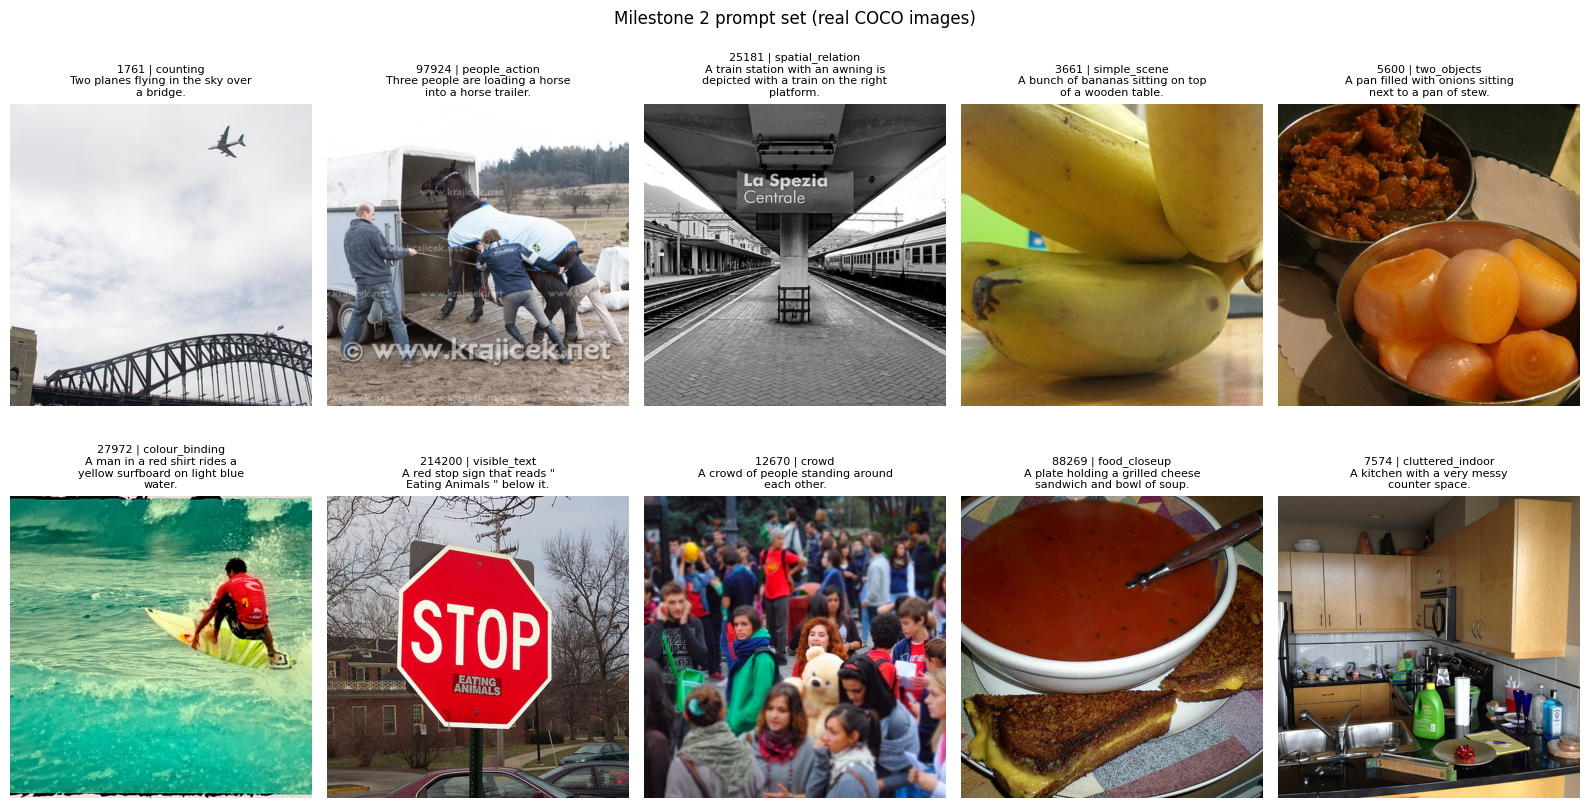

saved /content/drive/MyDrive/IE7615_Project2/results/milestone2/prompt_set_m2.png


In [11]:
show(ids, save=M2_RESULTS / "prompt_set_m2.png", title="Milestone 2 prompt set (real COCO images)")
print("saved", M2_RESULTS / "prompt_set_m2.png")